Turn downloaded demonstrations into organized examples a model can learn from

# Data preperation for LIBERO Goal

This notebook inspects demonstrations for the bowl-on-plate and bowl-on-stove tasks and prepares them for policy training.

### Locate the demonstration files

Import the tools and find both LIBERO-Goal task files. These files contain simulated demonstrations; opening them does not start the simulator.


In [1]:
from pathlib import Path #represents file and folder locations

import h5py 
import numpy as np
from PIL import Image
from IPython.display import display

project_dir = Path("/home/njmcmil/t2-project")

dataset_dir = (
    project_dir
    / "LIBERO"
    / "libero"
    / "datasets"
    / "libero_goal"
)

task_names = [
  "put_the_bowl_on_the_plate",
  "put_the_bowl_on_the_stove",
]

task_files = {
    task: dataset_dir / f"{task}_demo.hdf5"
    for task in task_names
}

for task, path in task_files.items():
    print(task)
    print("File exists:", path.is_file())

    if not path.is_file():
        raise FileNotFoundError(path)

put_the_bowl_on_the_plate
File exists: True
put_the_bowl_on_the_stove
File exists: True


### List the demonstrations

Read episode names from each file and sort them numerically. An episode contains many time steps, not just one image.


In [2]:
episodes_by_task = {}

for task, path in task_files.items():
    with h5py.File(path, "r") as demo_file:
        data = demo_file["data"]

        episode_names = sorted(
            data.keys(),
            key=lambda name: int(name.split("_")[-1])
        )

        episodes_by_task[task] = episode_names

        print("\nTask:", task)
        print("Demonstrations:", len(episode_names))
        print("First five:", episode_names[:5])


Task: put_the_bowl_on_the_plate
Demonstrations: 50
First five: ['demo_0', 'demo_1', 'demo_2', 'demo_3', 'demo_4']

Task: put_the_bowl_on_the_stove
Demonstrations: 50
First five: ['demo_0', 'demo_1', 'demo_2', 'demo_3', 'demo_4']


### Inspect one episode

Inspect observation keys and array dimensions. Images have time, height, width, and color axes; actions contain seven command values per time step.


In [3]:
task_name = task_names[0]
episode_name = episodes_by_task[task_name][0]

with h5py.File(task_files[task_name], "r") as demo_file:
    episode = demo_file["data"][episode_name]

    print("Task:", task_name)
    print("Episode:", episode_name)
    print("Episode contents:", list(episode.keys()))
    print("Observations:", list(episode["obs"].keys()))

    print(
        "External camera:",
        episode["obs"]["agentview_rgb"].shape
    )

    print(
        "Wrist camera:",
        episode["obs"]["eye_in_hand_rgb"].shape
    )

    print("Actions:", episode["actions"].shape)

  

Task: put_the_bowl_on_the_plate
Episode: demo_0
Episode contents: ['actions', 'dones', 'obs', 'rewards', 'robot_states', 'states']
Observations: ['agentview_rgb', 'ee_ori', 'ee_pos', 'ee_states', 'eye_in_hand_rgb', 'gripper_states', 'joint_states']
External camera: (90, 128, 128, 3)
Wrist camera: (90, 128, 128, 3)
Actions: (90, 7)


### Check shapes and usable pairs

Verify image counts, dimensions, and finite action values. Count one fewer usable pair than recorded actions because each saved image is paired with the following action.


In [4]:
camera_names = [
    "agentview_rgb",
    "eye_in_hand_rgb",
]

episode_lengths = {}

for task, path in task_files.items():
    episode_lengths[task] = {}

    with h5py.File(path, "r") as demo_file:
        for episode_name in episodes_by_task[task]:
            episode = demo_file["data"][episode_name]
            actions = episode["actions"][:]

            assert actions.ndim == 2
            assert actions.shape[1] == 7
            assert len(actions) > 0
            assert np.isfinite(actions).all()

            for camera in camera_names:
                images = episode["obs"][camera]

                assert images.shape == (
                    len(actions), 128, 128, 3
                )

                assert images.dtype == np.uint8

            assert len(actions) >= 2

            # Number of usable image → next-action pairs.
            episode_lengths[task][episode_name] = len(actions) - 1

    print(task, "passed the checks.")

put_the_bowl_on_the_plate passed the checks.
put_the_bowl_on_the_stove passed the checks.


### Select episode splits

Use a fixed seed to select 40 episodes per task: 28 training, 6 validation, and 6 test. Keep episodes whole. The next cell checks overlap under the declared initial-configuration grouping rule.


In [5]:
seed = 42
rng = np.random.default_rng(seed)

splits = {
    "train": {},
    "validation": {},
    "test": {},
}

unused_episodes = {}

for task in task_names:
    episode_names = episodes_by_task[task]

    assert len(episode_names) >= 40

    shuffled = rng.permutation(episode_names).tolist()

    splits["train"][task] = shuffled[:28]
    splits["validation"][task] = shuffled[28:34]
    splits["test"][task] = shuffled[34:40]

    unused_episodes[task] = shuffled[40:]

    train_set = set(splits["train"][task])
    validation_set = set(splits["validation"][task])
    test_set = set(splits["test"][task])

    assert train_set.isdisjoint(validation_set)
    assert train_set.isdisjoint(test_set)
    assert validation_set.isdisjoint(test_set)

    print("\nTask:", task)
    print("Training:", len(train_set))
    print("Validation:", len(validation_set))
    print("Test:", len(test_set))
    print("Unused:", len(unused_episodes[task]))


Task: put_the_bowl_on_the_plate
Training: 28
Validation: 6
Test: 6
Unused: 10

Task: put_the_bowl_on_the_stove
Training: 28
Validation: 6
Test: 6
Unused: 10


### Check timing and initial configurations

Compare recorded joint observations with the following simulator states to check the next-action pairing. Fingerprint rounded initial position configurations and check that no group crosses splits. This does not establish session independence or detect every similar scene.


In [6]:
import hashlib
import xml.etree.ElementTree as ET

initial_state_groups = {}
group_assignments = {}
timing_errors = []

for task, path in task_files.items():
    initial_state_groups[task] = {}

    with h5py.File(path, "r") as demo_file:
        for episode_name in episodes_by_task[task]:
            episode = demo_file["data"][episode_name]

            # Check the observed timing relationship.
            saved_joints = episode["obs"]["joint_states"][:-1]
            next_state_joints = episode["states"][1:, 1:8]

            timing_error = np.max(
                np.abs(saved_joints - next_state_joints)
            )

            timing_errors.append(float(timing_error))

            assert np.allclose(
                saved_joints,
                next_state_joints,
                rtol=0,
                atol=1e-6
            )

            # Determine the length of the simulator's position vector.
            model = ET.fromstring(episode.attrs["model_file"])
            worldbody = model.find("worldbody")

            position_sizes = {
                "free": 7,
                "ball": 4,
                "slide": 1,
                "hinge": 1,
            }

            number_of_positions = sum(
                position_sizes[joint.get("type", "hinge")]
                for joint in worldbody.findall(".//joint")
            )

            number_of_positions += (
                7 * len(worldbody.findall(".//freejoint"))
            )

            initial_state = np.asarray(
                episode.attrs["init_state"],
                dtype=np.float64
            )

            # Exclude simulation time and velocities.
            initial_positions = initial_state[
                1:1 + number_of_positions
            ]

            # Group configurations after rounding numerical precision.
            rounded_positions = np.round(initial_positions, 4)
            rounded_positions[rounded_positions == 0] = 0.0

            group_id = hashlib.sha256(
                rounded_positions.astype("<f8").tobytes()
            ).hexdigest()

            initial_state_groups[task][episode_name] = group_id

            for split_name, tasks in splits.items():
                if episode_name in tasks[task]:
                    group_assignments.setdefault(
                        group_id, set()
                    ).add(split_name)

cross_split_groups = {
    group_id: assignments
    for group_id, assignments in group_assignments.items()
    if len(assignments) > 1
}

assert not cross_split_groups, (
    "Related initial configurations cross splits. "
    "Rebuild the split by group before continuing."
)

print("Largest timing-check error:", max(timing_errors))
print("No rounded initial-configuration group crosses splits.")

Largest timing-check error: 0.0
No rounded initial-configuration group crosses splits.


### View an example

Display a training image and its next-action target. The vertical flip is only for viewing; model preprocessing retains the stored orientation.


Task: put_the_bowl_on_the_plate
Episode: demo_5
Time step: 0
Image shape: (128, 128, 3)
Action shape: (7,)
Recorded action: [ 0.25982143  0.08303571 -0.          0.          0.01392857 -0.
 -1.        ]


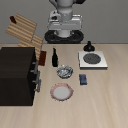

In [7]:
task_name = task_names[0]
episode_name = splits["train"][task_name][0]
timestep = 0

with h5py.File(task_files[task_name], "r") as demo_file:
    episode = demo_file["data"][episode_name]

    image = episode["obs"]["agentview_rgb"][timestep]
    action = episode["actions"][timestep + 1]

print("Task:", task_name)
print("Episode:", episode_name)
print("Time step:", timestep)
print("Image shape:", image.shape)
print("Action shape:", action.shape)
print("Recorded action:", action)

display(Image.fromarray(image[::-1]))

### Fit action normalization

Calculate one mean and scale per action component using only training targets. Validation and test must reuse these values. Near-zero standard deviations use scale 1 to avoid division by zero.


In [8]:
training_actions = []

for task in task_names:
    with h5py.File(task_files[task], "r") as demo_file:
        for episode_name in splits["train"][task]:
            actions = demo_file["data"][episode_name]["actions"][1:]
            training_actions.append(actions)

training_actions = np.concatenate(
    training_actions,
    axis=0
).astype(np.float64)

action_mean = training_actions.mean(axis=0)
action_std = training_actions.std(axis=0)

action_scale = np.where(
    action_std < 1e-6,
    1.0,
    action_std
)

print("Training action array:", training_actions.shape)
print("Mean:", action_mean)
print("Standard deviation:", action_std)
print("Scale used:", action_scale)

Training action array: (5442, 7)
Mean: [ 0.08250266  0.1030049  -0.16435216 -0.00818357  0.014621   -0.00875925
 -0.00220507]
Standard deviation: [0.4469149  0.24175296 0.53484815 0.02888642 0.05366166 0.0353067
 0.99999757]
Scale used: [0.4469149  0.24175296 0.53484815 0.02888642 0.05366166 0.0353067
 0.99999757]


### Define preprocessing

Scale image pixels to 0–1 and rearrange HWC to CHW. Normalize action targets and verify that undoing normalization recovers the original command.


In [9]:
def prepare_image(image):
    image = image.astype(np.float32) / 255.0
    image = image.transpose(2, 0, 1)

    return np.ascontiguousarray(image)


def normalize_action(action):
    normalized = (action - action_mean) / action_scale

    return normalized.astype(np.float32)


def recover_action(normalized_action):
    return normalized_action * action_scale + action_mean


prepared_image = prepare_image(image)
normalized_action = normalize_action(action)
recovered_action = recover_action(normalized_action)

print("Prepared image:", prepared_image.shape)
print("Pixel range:", prepared_image.min(), prepared_image.max())
print("Normalized action:", normalized_action)

assert np.allclose(
    recovered_action,
    action,
    atol=1e-6
)

print("Converting back recovered the original action.")

Prepared image: (3, 128, 128)
Pixel range: 0.0 0.91764706
Normalized action: [ 0.39676183 -0.08260163  0.3072875   0.2833017  -0.01290366  0.24809039
 -0.99779737]
Converting back recovered the original action.


### Index training examples

Store task, episode, and time-step addresses for all usable training examples. This list stores locations rather than loading every image into memory.


In [10]:
training_index = []

for task in task_names:
    for episode_name in splits["train"][task]:
        number_of_steps = episode_lengths[task][episode_name]

        for timestep in range(number_of_steps):
            training_index.append(
                (task, episode_name, timestep)
            )

print("Number of training examples:", len(training_index))
print("First three example locations:", training_index[:3])

Number of training examples: 5442
First three example locations: [('put_the_bowl_on_the_plate', 'demo_5', 0), ('put_the_bowl_on_the_plate', 'demo_5', 1), ('put_the_bowl_on_the_plate', 'demo_5', 2)]


### Build a practice batch

Load 16 matched examples from both cameras, together with action targets and instructions. Stack them into batch arrays to verify the format expected by training.


In [11]:
batch_size = 16
batch_rng = np.random.default_rng(seed)

selected_indices = batch_rng.choice(
    len(training_index),
    size=batch_size,
    replace=False
)

image_lists = {
    camera: []
    for camera in camera_names
}

action_list = []
instruction_list = []

instructions_by_task = {
    "put_the_bowl_on_the_plate": "put the bowl on the plate",
    "put_the_bowl_on_the_stove": "put the bowl on the stove",
}

for index in selected_indices:
    task, episode_name, timestep = training_index[int(index)]

    with h5py.File(task_files[task], "r") as demo_file:
        episode = demo_file["data"][episode_name]

        for camera in camera_names:
            raw_image = episode["obs"][camera][timestep]
            image_lists[camera].append(
                prepare_image(raw_image)
            )

        raw_action = episode["actions"][timestep + 1]
        action_list.append(
            normalize_action(raw_action)
        )

    instruction_list.append(instructions_by_task[task])

image_batch = {
    camera: np.stack(images)
    for camera, images in image_lists.items()
}

action_batch = np.stack(action_list)

for camera, images in image_batch.items():
    print(camera, images.shape)

print("Actions:", action_batch.shape)
print("Number of instructions:", len(instruction_list))

assert action_batch.shape == (batch_size, 7)

for images in image_batch.values():
    assert images.shape == (batch_size, 3, 128, 128)

agentview_rgb (16, 3, 128, 128)
eye_in_hand_rgb (16, 3, 128, 128)
Actions: (16, 7)
Number of instructions: 16


### Record metadata and counts

Read task instructions, image conventions, and recorded environment settings. Count episodes and usable image/action pairs separately for each split.


In [12]:
import json

dataset_metadata = {}

for task, path in task_files.items():
    with h5py.File(path, "r") as demo_file:
        data = demo_file["data"]

        problem_info = json.loads(
            data.attrs["problem_info"]
        )

        environment_info = json.loads(
            data.attrs["env_args"]
        )

        dataset_metadata[task] = {
            "file": str(path.relative_to(project_dir)),
            "available_episodes": len(episodes_by_task[task]),
            "language_instruction": (
                problem_info["language_instruction"]
            ),
            "image_convention": str(
                data.attrs["macros_image_convention"]
            ),
            "recorded_environment": environment_info,
        }

        assert (
            dataset_metadata[task]["language_instruction"]
            == instructions_by_task[task]
        )

        print(
            task,
            "— image convention:",
            dataset_metadata[task]["image_convention"]
        )

split_counts = {}

for split_name, tasks in splits.items():
    split_counts[split_name] = {}

    for task, episode_names in tasks.items():
        split_counts[split_name][task] = {
            "episodes": len(episode_names),
            "usable_pairs": sum(
                episode_lengths[task][name]
                for name in episode_names
            ),
        }

print(json.dumps(split_counts, indent=2))

put_the_bowl_on_the_plate — image convention: opengl
put_the_bowl_on_the_stove — image convention: opengl
{
  "train": {
    "put_the_bowl_on_the_plate": {
      "episodes": 28,
      "usable_pairs": 2600
    },
    "put_the_bowl_on_the_stove": {
      "episodes": 28,
      "usable_pairs": 2842
    }
  },
  "validation": {
    "put_the_bowl_on_the_plate": {
      "episodes": 6,
      "usable_pairs": 568
    },
    "put_the_bowl_on_the_stove": {
      "episodes": 6,
      "usable_pairs": 584
    }
  },
  "test": {
    "put_the_bowl_on_the_plate": {
      "episodes": 6,
      "usable_pairs": 579
    },
    "put_the_bowl_on_the_stove": {
      "episodes": 6,
      "usable_pairs": 573
    }
  }
}


### Save preparation artifacts

Save split selections, grouping rules, preprocessing, metadata, and training-only normalization. A fingerprint links the statistics to the manifest. Different existing contents trigger an error rather than silently replacing the experiment plan.


In [13]:
output_dir = project_dir / "configs" / "data_preparation"

manifest = {
    "seed": seed,
    "source": {
        "dataset": "LIBERO-Goal simulated demonstrations",
        "download_location": (
            "https://huggingface.co/datasets/"
            "yifengzhu-hf/LIBERO-datasets"
        ),
    },
    "tasks": dataset_metadata,
    "splits": splits,
    "unused_episodes": unused_episodes,
    "counts": split_counts,
    "initial_state_groups": initial_state_groups,
    "grouping_rule": (
        "Initial simulator position configuration, excluding "
        "time and velocities, rounded to four decimal places."
    ),
    "grouping_limitation": (
        "This does not establish collection-session independence "
        "or identify every semantically similar configuration."
    ),
    "preprocessing": {
        "cameras": camera_names,
        "image_layout": "CHW",
        "image_dtype": "float32",
        "image_scaling": "divide by 255",
        "image_orientation": "preserve stored OpenGL orientation",
        "resize": None,
        "action_target": "actions[t + 1] for observation[t]",
        "excluded_data": "final observation and first action",
        "action_normalization": "training-only mean and scale",
    },
    "verification": {
        "array_shapes": True,
        "timing_max_joint_error": max(timing_errors),
        "initial_group_overlap": False,
        "autonomous_observation_action_compatibility": "pending",
    },
}

# Link the statistics to the exact preparation manifest.
manifest_text = json.dumps(
    manifest,
    indent=2,
    sort_keys=True
) + "\n"

manifest_hash = hashlib.sha256(
    manifest_text.encode("utf-8")
).hexdigest()

normalization = {
    "manifest_sha256": manifest_hash,
    "fit_split": "train",
    "training_pairs": len(training_actions),
    "mean": action_mean.tolist(),
    "standard_deviation": action_std.tolist(),
    "scale": action_scale.tolist(),
    "near_constant_threshold": 1e-6,
}

normalization_text = json.dumps(
    normalization,
    indent=2,
    sort_keys=True
) + "\n"

files_to_save = {
    "split_manifest.json": manifest_text,
    "action_normalization.json": normalization_text,
}

# Check all destinations before writing either file.
for filename, text in files_to_save.items():
    destination = output_dir / filename

    if destination.exists():
        if destination.read_text(encoding="utf-8") != text:
            raise FileExistsError(
                f"Existing preparation differs: {destination}. "
                "Review it before replacing an experiment's data plan."
            )

output_dir.mkdir(parents=True, exist_ok=True)

for filename, text in files_to_save.items():
    destination = output_dir / filename
    destination.write_text(text, encoding="utf-8")

    assert json.loads(
        destination.read_text(encoding="utf-8")
    ) == json.loads(text)

    print("Saved:", destination)

Saved: /home/njmcmil/t2-project/configs/data_preparation/split_manifest.json
Saved: /home/njmcmil/t2-project/configs/data_preparation/action_normalization.json
